# Grad-CAM on the robot's object tour, and on my bird photo

`gradcam.ipynb` showed *where* the CNN looks on my car photos and the first Webots images. This notebook does the same for:

1. **A new photo of my own: a bird** (an Asian glossy starling on a wall). "Bird" is one of the ten CIFAR-10 classes.
2. **The photos the e-puck took during the CNN object tour** in Webots (`webots_object_tour/`, world `cnn_objects.wbt`): truck, horse, car, deer and the paper boat.

Grad-CAM needs gradients, so it runs on the full Keras model (`cifar10_cnn.keras`), not the int8 TensorFlow Lite model on the robot. The preprocessing is the robot's (centre square crop, `INTER_AREA` resize to 32×32), and the int8 model's answer is printed next to it to show the two agree.

In [1]:
import pathlib, re
import numpy as np, cv2 as cv, matplotlib.pyplot as plt, tensorflow as tf, keras
from PIL import Image as PILImage

CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
OUT = pathlib.Path("results/gradcam"); OUT.mkdir(parents=True, exist_ok=True)
model = keras.models.load_model("results/models/cifar10_cnn.keras")
LAST_CONV = "activation_5"  # last conv block output (8x8x128), as in gradcam.ipynb
grad_model = keras.Model(model.inputs, [model.get_layer(LAST_CONV).output, model.output])
int8 = tf.lite.Interpreter(model_path="results/models/cifar10_cnn_int8.tflite"); int8.allocate_tensors()
i8_in, i8_out = int8.get_input_details()[0], int8.get_output_details()[0]

def load_for_cnn(path):
    rgb = np.asarray(PILImage.open(path).convert("RGB")); h, w = rgb.shape[:2]; s = min(w, h)
    crop = rgb[(h - s) // 2:(h - s) // 2 + s, (w - s) // 2:(w - s) // 2 + s]
    return cv.resize(crop, (32, 32), interpolation=cv.INTER_AREA).astype("float32") / 255.0

def grad_cam(x):
    with tf.GradientTape() as tape:
        maps, logits = grad_model(x[None], training=False)
        cls = int(tf.argmax(logits[0])); score = logits[:, cls]
    grads = tape.gradient(score, maps)[0]
    weights = tf.reduce_mean(grads, axis=(0, 1))
    cam = tf.nn.relu(tf.reduce_sum(maps[0] * weights, axis=-1)).numpy()
    cam = cv.resize(cam, (32, 32), interpolation=cv.INTER_CUBIC)
    cam = np.clip(cam, 0, None); cam = cam / cam.max() if cam.max() > 0 else cam
    return cam, cls, tf.nn.softmax(logits[0]).numpy()

def int8_label(x):
    s, z = i8_in["quantization"]
    int8.set_tensor(i8_in["index"], np.round(x[None] / s + z).clip(-128, 127).astype(i8_in["dtype"])); int8.invoke()
    q = int8.get_tensor(i8_out["index"])[0].astype(np.float32); s2, z2 = i8_out["quantization"]
    return CLASS_NAMES[int(np.argmax((q - z2) * s2))]

def overlay(x, cam):
    return np.clip(0.55 * x + 0.45 * plt.cm.jet(cam)[..., :3], 0, 1)

## 1. My bird photo

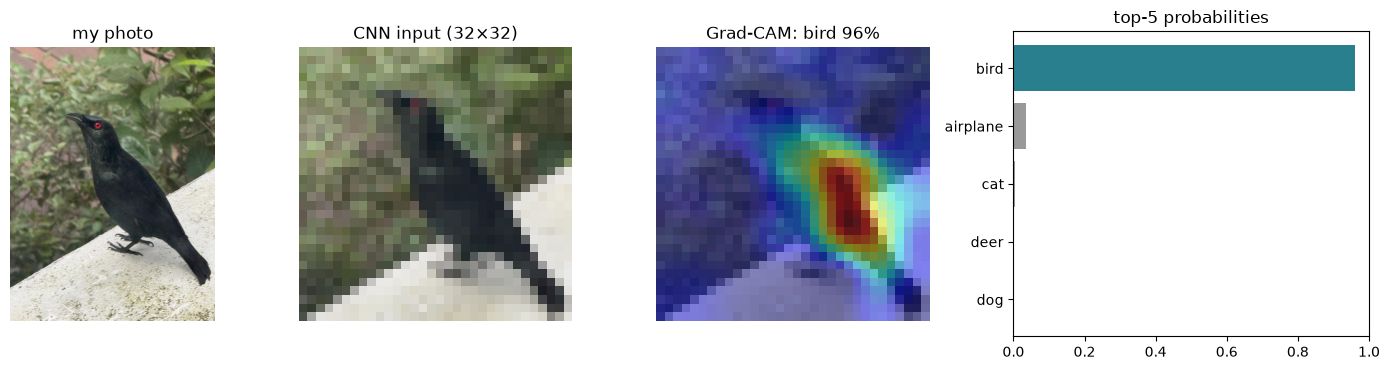

Keras: bird 95.9%   int8 (robot model): bird
top-5: bird 95.9%, airplane 3.5%, cat 0.3%, deer 0.1%, dog 0.1%


In [2]:
path = "my_photos/bird_01.jpg"
x = load_for_cnn(path); cam, cls, p = grad_cam(x); top = np.argsort(p)[::-1][:5]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), gridspec_kw={"width_ratios": [0.75, 1, 1, 1.3]})
axes[0].imshow(PILImage.open(path)); axes[0].set_title("my photo")
axes[1].imshow(x); axes[1].set_title("CNN input (32×32)")
axes[2].imshow(overlay(x, cam)); axes[2].set_title(f"Grad-CAM: {CLASS_NAMES[cls]} {p[cls]:.0%}")
for ax in axes[:3]: ax.axis("off")
axes[3].barh([CLASS_NAMES[i] for i in top][::-1], p[top][::-1], color=["#2A7F8E" if i == 2 else "#999999" for i in top][::-1])
axes[3].set_xlim(0, 1); axes[3].set_title("top-5 probabilities")
plt.tight_layout(); fig.savefig(OUT / "gradcam_bird.png", dpi=170); plt.show()
print(f"Keras: {CLASS_NAMES[cls]} {p[cls]:.1%}   int8 (robot model): {int8_label(x)}")
print("top-5:", ", ".join(f"{CLASS_NAMES[i]} {p[i]:.1%}" for i in top))

## 2. The robot's photos from the CNN object tour

truck  view 2: Keras truck        90%  int8 truck     
horse  view 2: Keras horse       100%  int8 horse     
car    view 1: Keras automobile  100%  int8 automobile
deer   view 2: Keras deer         95%  int8 deer      
boat   view 1: Keras airplane     81%  int8 airplane  


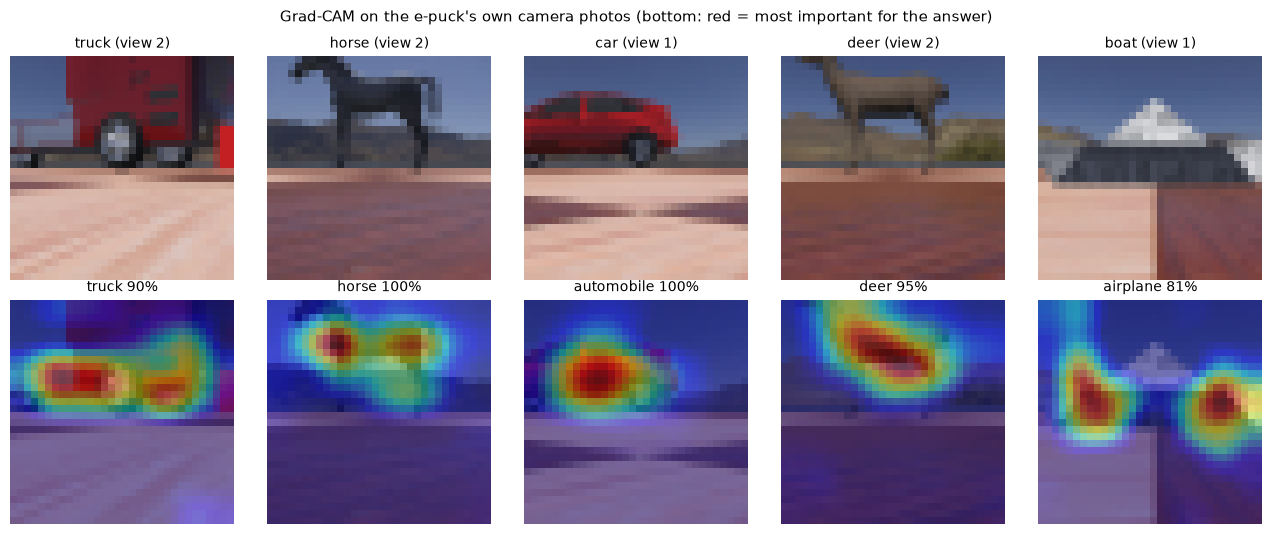

In [3]:
tour = pathlib.Path("webots_object_tour")
CASES = [("truck", 2), ("horse", 2), ("car", 1), ("deer", 2), ("boat", 1)]
fig, axes = plt.subplots(2, len(CASES), figsize=(2.6 * len(CASES), 5.4))
for col, (name, view) in enumerate(CASES):
    f = next(tour.glob(f"*_{name}_view{view}.png"))
    x = load_for_cnn(f); cam, cls, p = grad_cam(x)
    axes[0, col].imshow(x); axes[0, col].set_title(f"{name} (view {view})", fontsize=10)
    axes[1, col].imshow(overlay(x, cam)); axes[1, col].set_title(f"{CLASS_NAMES[cls]} {p[cls]:.0%}", fontsize=10)
    for ax in axes[:, col]: ax.axis("off")
    print(f"{name:6s} view {view}: Keras {CLASS_NAMES[cls]:10s} {p[cls]:5.0%}  int8 {int8_label(x):10s}")
fig.suptitle("Grad-CAM on the e-puck's own camera photos (bottom: red = most important for the answer)", fontsize=11)
plt.tight_layout(); fig.savefig(OUT / "gradcam_tour.png", dpi=170); plt.show()

## What this shows

- **My bird photo is classified correctly: bird, 96%** (the int8 robot model also says bird). The heat sits on the bird's body and the line of its back and tail against the pale wall, not on the leaves behind it. Unlike the Webots animals, the CNN is looking at the animal here, and a dark bird on a ledge with foliage behind is a very CIFAR-10-like picture.
- **On the robot's own photos the CNN also looks at the object:** the truck's wheels and lower body, the horse's head, neck and hindquarters, the car's body, the deer's body. These are the same answers the robot gave in the tour.
- **The paper boat, called "airplane" (81%), shows why.** The heat is on the boat's two pointed ends, not its middle: two tips sticking out sideways against the hills and sky, like an airplane's wings. With no water in the picture, nothing points to "ship". This is the shape-plus-scenery shortcut seen in `webots_animals.ipynb` and Section 4.5 of the report.
- Grad-CAM is computed on the Keras model because the int8 robot model has no gradients. The two models agree on every image here.